Connected to Python 3.12.4

In [ ]:
import duckdb
import pandas as pd
import re
import psutil
import numpy as np
import pyfixest as pf
import gc
import matplotlib.pyplot as plt
from pathlib import Path
import geopandas as gpd
import statsmodels.formula.api as smf

pd.options.display.float_format = '{:.2f}'.format  
pd.set_option('display.max_columns', None)  # Show all columns in DataFrame output

current_dir = Path(__file__)
gitfolder = current_dir.parent.parent
datafolder = current_dir.parent.parent.parent / 'data'
output = gitfolder / 'output' 

In [ ]:
# Connect to DuckDB
con = duckdb.connect()

# Define file paths
base_path = datafolder / "Aggregate Data"
#months = ["june", "july", "aug", "sep", "oct", "nov"]
months = ["june"]

# Read the first month's data to determine column structure
sample_query = f"SELECT * FROM read_parquet('{base_path / (months[0] + '_data_week_store_sku.parquet')}') LIMIT 1"
sample_data = con.execute(sample_query).df()

# Detect column types
column_types = sample_data.dtypes.map(str).replace({
    'int64': 'BIGINT',
    'float64': 'DOUBLE',
    'object': 'VARCHAR'
}).to_dict()


# Create merged_data table with the same columns + "ppu"
columns = list(sample_data.columns) + ["ppu"]
column_types["ppu"] = "DOUBLE"

# Create table dynamically
col_str = ", ".join(f"{col} {column_types[col]}" for col in columns)
create_query = f"CREATE TABLE merged_data ({col_str})"
con.execute(create_query)

# Process each month separately and append to the table
for month in months:
    # Read data directly in DuckDB
    print(f"Processing {month}...")
    data_query = f"SELECT * FROM read_parquet('{base_path / (month + '_data_week_store_sku.parquet')}')"
    mode_query = f"SELECT week, sku_gtin, store_id, ppu FROM read_parquet('{base_path / (month + '_modes_week_store_sku.parquet')}')"

    # Merge inside DuckDB, ensuring column match
    merge_query = f"""
        INSERT INTO merged_data ({', '.join(columns)})
        SELECT d.*, m.ppu 
        FROM ({data_query}) AS d
        LEFT JOIN ({mode_query}) AS m 
        USING (week, sku_gtin, store_id)
    """
    
    con.execute(merge_query)
    print(f"Processed {month}")

df_full = con.execute("SELECT * FROM merged_data").df()

Processing june...
Processed june


In [ ]:
def check_memory():
    memory = psutil.virtual_memory()
    print(f"Total memory: {memory.total / (1024**3):.2f} GB")
    print(f"Available memory: {memory.available / (1024**3):.2f} GB")
    print(f"Used memory: {memory.used / (1024**3):.2f} GB")
    print(f"Memory usage: {memory.percent}%")

In [ ]:
df_subset = df_full[(df_full['price'] > 0) & (df_full['price'] < 1000) & (df_full['quantity'] > 0) &  (df_full['quantity'] < 201)]

del df_full
gc.collect()

34

In [ ]:
kassalapp = pd.read_feather(f'{datafolder}\\kassalapp_data_food.ftr')
kassalapp.ean = kassalapp.ean.astype('category')
kassalapp.brand_id = kassalapp.brand_id.astype('category')
kassalapp.category_id = kassalapp.category_id.astype('category')
kassalapp.category_name = kassalapp.category_name.astype('category')
kassalapp.parent_category_name = kassalapp.parent_category_name.astype('category')
kassalapp_short = kassalapp[['ean', 'brand_id', 'category_id', 'category_name', 'parent_category_name']].drop_duplicates()

df_subset = df_subset.merge(kassalapp_short, left_on='sku_gtin', right_on='ean', how='left')

In [ ]:
product_unique = df_subset.groupby('sku_gtin', as_index=False).agg({'store_id': 'nunique', 'week': 'nunique'})

product_nonunique = product_unique[(product_unique['store_id'] > 1) & (product_unique['week'] > 1)].sku_gtin.unique()

df_nonunique = df_subset[df_subset['sku_gtin'].isin(product_nonunique)].copy()

del df_subset
gc.collect()

check_memory()

Total memory: 150.00 GB
Available memory: 121.40 GB
Used memory: 28.59 GB
Memory usage: 19.1%


In [ ]:
df_subset.parent_category_name.nunique()

NameError: name 'df_subset' is not defined

In [ ]:
df_nonunique.parent_category_name.nunique()

123

In [ ]:
df_nonunique.parent_category_name.value_counts()

parent_category_name
Snacks & godteri     5211003
Drikke               3799601
Kioskvarer           2648273
Sauser               1820605
Pålegg & frokost     1669080
                      ...   
Dessert og iskrem          0
Kjøttretter                0
Hamburger                  0
Stearinlys                 0
Vin                        0
Name: count, Length: 129, dtype: int64

In [ ]:
df_cat = df_nonunique[df_nonunique['parent_category_name'] == 'Sauser'].copy()

In [ ]:
del df_nonunique
gc.collect()

500

In [ ]:
check_memory()

Total memory: 150.00 GB
Available memory: 128.78 GB
Used memory: 21.22 GB
Memory usage: 14.1%


In [ ]:
df_cat

,week,sku_gtin,store_id,kjedeid,trans,price,quantity,ppu,ean,brand_id,category_id,category_name,parent_category_name
328,23.00,5012427334403.00,7080000062881,meny,4.00,43.50,4.00,43.50,5012427334403,1974.00,2193.00,Myntesaus,Sauser
339,23.00,5011308700375.00,7080001080839,meny,1.00,29.90,1.00,29.90,5011308700375,1196.00,371.00,Asiatiske sauser,Sauser
340,23.00,5011308700375.00,7080001080839,meny,1.00,29.90,1.00,29.90,5011308700375,1684.00,371.00,Asiatiske sauser,Sauser
364,23.00,8005110551215.00,7080001386030,kiwi,2.00,12.90,2.00,12.90,8005110551215,347.00,423.00,Pizzasaus,Sauser
366,23.00,8005110551215.00,7080001386030,kiwi,2.00,12.90,2.00,12.90,8005110551215,NaN,423.00,Pizzasaus,Sauser
...,...,...,...,...,...,...,...,...,...,...,...,...,...
98032629,22.00,7039010524766.00,7080001165093,Rema,3.00,22.40,3.00,22.40,7039010524766,213.00,2387.00,Ravigottesaus,Sauser
98032637,22.00,7311310034061.00,7080001416430,Rema,1.00,22.40,1.00,22.40,7311310034061,165.00,371.00,Asiatiske sauser,Sauser
98032776,22.00,7037610232043.00,7080001232429,Rema,4.00,19.90,4.00,19.90,7037610232043,33.00,763.00,Soppsaus,Sauser
98032777,22.00,7037610232043.00,7080001232429,Rema,4.00,19.90,4.00,19.90,7037610232043,150.00,763.00,Soppsaus,Sauser


In [ ]:
model_iv1 = pf.feols('log_quantity ~ log_price | sku_gtin + store_id', data=df_cat, vcov = {'CRV1':'store_id'})
model_iv1.summary()
del model_iv1
gc.collect()

FactorEvaluationError: Unable to evaluate factor `log_quantity`. [NameError: `log_quantity` is not present in the dataset or evaluation context.]

In [ ]:
df_cat['log_price'] = np.log(df_cat['ppu'])
df_cat['log_quantity'] = np.log(df_cat['quantity'])
df_cat['log_trans'] = np.log(df_cat['trans'])

In [ ]:
model_iv1 = pf.feols('log_quantity ~ log_price | sku_gtin + store_id', data=df_cat, vcov = {'CRV1':'store_id'})
model_iv1.summary()
del model_iv1
gc.collect()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.925 |        0.022 |   -41.766 |      0.000 | -0.969 |  -0.882 |
---
RMSE: 0.686 R2: 0.399 R2 Within: 0.009 


372

In [ ]:
np.floor(45)

np.float64(45.0)

In [ ]:
np.floor(45.5)

np.float64(45.0)

In [ ]:
def krone_ore_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dK: distance to lower decade in kroner (49.90 -> 9)
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to lower 10-krone threshold
    dK = 1 - (krone_part/10 - np.floor(krone_part / 10))
    # Distance to 0 ore
    dO = ore_part

    return dK

In [ ]:
def krone_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dK: distance to lower decade in kroner (49.90 -> 9)
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to lower 10-krone threshold
    dK = 1 - (krone_part/10 - np.floor(krone_part / 10))
    # Distance to 0 ore
    dO = ore_part

    return dK

In [ ]:
krone_distance(45.5)

np.float64(0.5)

In [ ]:
krone_distance(49)

np.float64(0.09999999999999964)

In [ ]:
krone_distance(41)

np.float64(0.9000000000000004)

In [ ]:
krone_distance(40)

np.float64(1.0)

In [ ]:
krone_distance(40/3)

np.float64(0.7)

In [ ]:
krone_distance(40.3)

np.float64(1.0)

In [ ]:
krone_distance(41.3)

np.float64(0.9000000000000004)

In [ ]:
def krone_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dK: distance to lower decade in kroner (49.90 -> 9)
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to lower 10-krone threshold
    dK = 1 - (krone_part/10 - np.floor(krone_part / 10))
    # Distance to 0 ore
    dO = ore_part

    return dK

def ore_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to 0 ore
    dO = ore_part

    return dO

In [ ]:
ore_distance(49.9)

np.float64(0.8999999999999986)

In [ ]:
def krone_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dK: distance to lower decade in kroner (49.90 -> 9)
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to lower 10-krone threshold
    dK = 1 - (krone_part/10 - np.floor(krone_part / 10))
    # Distance to 0 ore
    dO = ore_part

    return dK

def ore_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to 0 ore
    dO = 1 - ore_part

    return dO

In [ ]:
ore_distance(49.9)

np.float64(0.10000000000000142)

In [ ]:
ore_distance(49.8)

np.float64(0.20000000000000284)

In [ ]:
ore_distance(49.1)

np.float64(0.8999999999999986)

In [ ]:
ore_distance(49.02)

np.float64(0.9799999999999969)

In [ ]:
ore_distance(49.0)

np.float64(1.0)

In [ ]:
df_cat["dK"] = krone_distance(df_cat["price"])
df_cat["dO"] = ore_distance(df_cat["price"])

In [ ]:
model_iv1 = pf.feols('log_quantity ~ log_price | sku_gtin + store_id', data=df_cat, vcov = {'CRV1':'store_id'})
model_iv1.summary()
del model_iv1
gc.collect()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.925 |        0.022 |   -41.766 |      0.000 | -0.969 |  -0.882 |
---
RMSE: 0.686 R2: 0.399 R2 Within: 0.009 


372

In [ ]:
model1 = pf.feols('log_quantity ~ log_price | sku_gtin + store_id', data=df_cat, vcov = {'CRV1':'store_id'})
model1.summary()
del model1   
gc.collect()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.925 |        0.022 |   -41.766 |      0.000 | -0.969 |  -0.882 |
---
RMSE: 0.686 R2: 0.399 R2 Within: 0.009 


372

In [ ]:
model1 = pf.feols('log_quantity ~ log_price | sku_gtin + store_id + week', data=df_cat, vcov = {'CRV1':'store_id'})
model1.summary()
del model1   
gc.collect()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id+week
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.971 |        0.023 |   -42.449 |      0.000 | -1.016 |  -0.926 |
---
RMSE: 0.652 R2: 0.457 R2 Within: 0.01 


412

In [ ]:
model2 = pf.feols('log_quantity ~ log_price + dK + dO | sku_gtin + store_id + week', data=df_cat, vcov = {'CRV1':'store_id'})
model2.summary()
del model2   
gc.collect()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id+week
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.959 |        0.023 |   -41.954 |      0.000 | -1.003 |  -0.914 |
| dK            |     -0.023 |        0.005 |    -4.467 |      0.000 | -0.033 |  -0.013 |
| dO            |      0.082 |        0.006 |    12.911 |      0.000 |  0.069 |   0.094 |
---
RMSE: 0.651 R2: 0.458 R2 Within: 0.011 


470

In [ ]:
df_cat.head()

,week,sku_gtin,store_id,kjedeid,trans,price,quantity,ppu,ean,brand_id,category_id,category_name,parent_category_name,log_price,log_quantity,log_trans,dK,dO
328,23.00,5012427334403.00,7080000062881,meny,4.00,43.50,4.00,43.50,5012427334403,1974.00,2193.00,Myntesaus,Sauser,3.77,1.39,1.39,0.70,0.50
339,23.00,5011308700375.00,7080001080839,meny,1.00,29.90,1.00,29.90,5011308700375,1196.00,371.00,Asiatiske sauser,Sauser,3.40,0.00,0.00,0.10,0.10
340,23.00,5011308700375.00,7080001080839,meny,1.00,29.90,1.00,29.90,5011308700375,1684.00,371.00,Asiatiske sauser,Sauser,3.40,0.00,0.00,0.10,0.10
364,23.00,8005110551215.00,7080001386030,kiwi,2.00,12.90,2.00,12.90,8005110551215,347.00,423.00,Pizzasaus,Sauser,2.56,0.69,0.69,0.80,0.10
366,23.00,8005110551215.00,7080001386030,kiwi,2.00,12.90,2.00,12.90,8005110551215,NaN,423.00,Pizzasaus,Sauser,2.56,0.69,0.69,0.80,0.10


In [ ]:
df_cat['log_price'] = np.log(df_cat['ppu'])
df_cat['log_quantity'] = np.log(df_cat['quantity'])
df_cat['log_trans'] = np.log(df_cat['trans'])
df_cat["dK"] = krone_distance(df_cat["ppu"])
df_cat["dO"] = ore_distance(df_cat["ppu"])

In [ ]:
model2 = pf.feols('log_quantity ~ log_price + dK + dO | sku_gtin + store_id + week', data=df_cat, vcov = {'CRV1':'store_id'})
model2.summary()
del model2   
gc.collect()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id+week
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.977 |        0.023 |   -43.106 |      0.000 | -1.022 |  -0.933 |
| dK            |     -0.021 |        0.005 |    -4.118 |      0.000 | -0.032 |  -0.011 |
| dO            |     -0.024 |        0.007 |    -3.661 |      0.000 | -0.037 |  -0.011 |
---
RMSE: 0.652 R2: 0.458 R2 Within: 0.01 


470

In [ ]:
model2 = pf.feols('log_quantity ~ log_price + dK + dO | sku_gtin + store_id + week', data=df_cat, vcov = {'CRV1':'store_id'})
model2.summary()

###

Estimation:  OLS
Dep. var.: log_quantity, Fixed effects: sku_gtin+store_id+week
Inference:  CRV1
Observations:  1820605

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_price     |     -0.977 |        0.023 |   -43.106 |      0.000 | -1.022 |  -0.933 |
| dK            |     -0.021 |        0.005 |    -4.118 |      0.000 | -0.032 |  -0.011 |
| dO            |     -0.024 |        0.007 |    -3.661 |      0.000 | -0.037 |  -0.011 |
---
RMSE: 0.652 R2: 0.458 R2 Within: 0.01 


In [ ]:
coef = model2.coef()

In [ ]:
print(coef)

Coefficient
log_price   -0.98
dK          -0.02
dO          -0.02
Name: Estimate, dtype: float64


In [ ]:
prices = np.round(np.arange(10.00, 100.00, 0.01), 2)

In [ ]:
prices

array([10.  , 10.01, 10.02, ..., 99.97, 99.98, 99.99])

In [ ]:
K = np.floor(prices).astype(int)
O = prices - K

dK = K - 10 * (K // 10)   # distance to lower decade (49.90 -> 9)
dO = O                   # distance to 0 ore (49.90 -> 0.90)

In [ ]:
dK

array([0, 0, 0, ..., 9, 9, 9])

In [ ]:
dK = [krone_distance(p) for p in prices]   # distance to lower decade (49.90 -> 9)

In [ ]:
dK

[np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float6

In [ ]:
dO = [ore_distance(p) for p in prices]                   # distance to 0 ore (49.90 -> 0.90)

In [ ]:
pred_df = pd.DataFrame({
    "price": prices,
    "log_price": np.log(prices),
    "dK": dK,
    "dO": dO
})

In [ ]:
pred_df["log_q_hat"] = (
    coef["log_price"] * pred_df["log_price"]
    + coef["dK"] * pred_df["dK"]
    + coef["dO"] * pred_df["dO"]
)

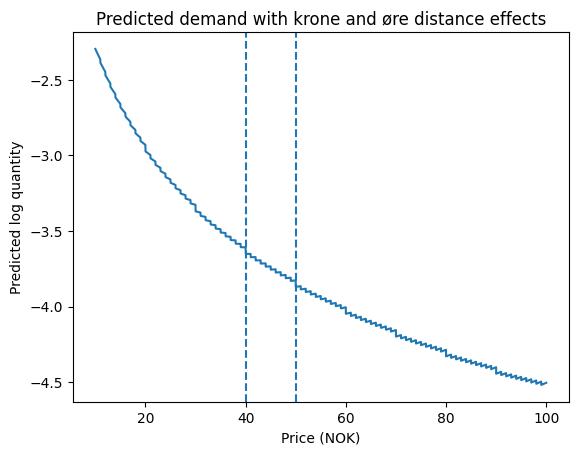

In [ ]:
plt.figure()
plt.plot(pred_df["price"], pred_df["log_q_hat"])
plt.axvline(40, linestyle="--")
plt.axvline(50, linestyle="--")
plt.xlabel("Price (NOK)")
plt.ylabel("Predicted log quantity")
plt.title("Predicted demand with krone and øre distance effects")
plt.show()

In [ ]:
prices = np.round(np.arange(40.00, 50.00, 0.01), 2)

dK = [krone_distance(p) for p in prices] # distance to lower decade (49.90 -> 9)
dO = [ore_distance(p) for p in prices] # distance to 0 ore (49.90 -> 0.90)

pred_df = pd.DataFrame({
    "price": prices,
    "log_price": np.log(prices),
    "dK": dK,
    "dO": dO
})

coef = model2.coef()

pred_df["log_q_hat"] = (
    coef["log_price"] * pred_df["log_price"]
    + coef["dK"] * pred_df["dK"]
    + coef["dO"] * pred_df["dO"]
)

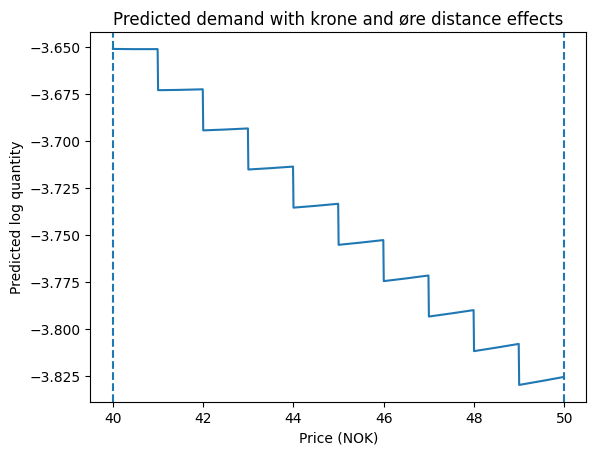

In [ ]:
plt.figure()
plt.plot(pred_df["price"], pred_df["log_q_hat"])
plt.axvline(40, linestyle="--")
plt.axvline(50, linestyle="--")
plt.xlabel("Price (NOK)")
plt.ylabel("Predicted log quantity")
plt.title("Predicted demand with krone and øre distance effects")
plt.show()

In [ ]:
plt.figure()
plt.plot(pred_df["price"], pred_df["q_hat"])
plt.axvline(40, linestyle="--")
plt.axvline(50, linestyle="--")
plt.xlabel("Price (NOK)")
plt.ylabel("Predicted quantity")
plt.title("Predicted demand with krone and øre distance effects")
plt.show()

KeyError: 'q_hat'

<Figure size 640x480 with 0 Axes>

In [ ]:
pred_df["q_hat"] = np.exp(pred_df["log_q_hat"])

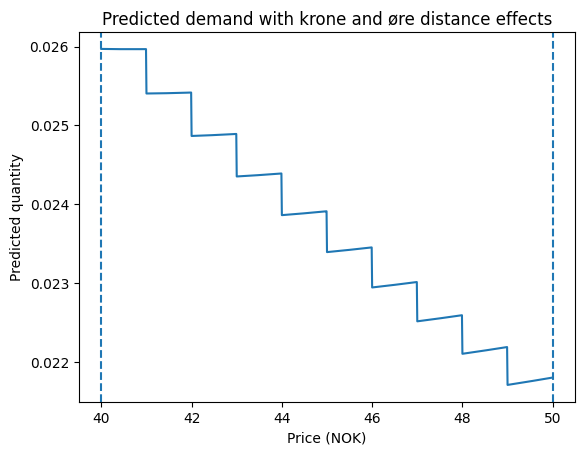

In [ ]:
plt.figure()
plt.plot(pred_df["price"], pred_df["q_hat"])
plt.axvline(40, linestyle="--")
plt.axvline(50, linestyle="--")
plt.xlabel("Price (NOK)")
plt.ylabel("Predicted quantity")
plt.title("Predicted demand with krone and øre distance effects")
plt.show()

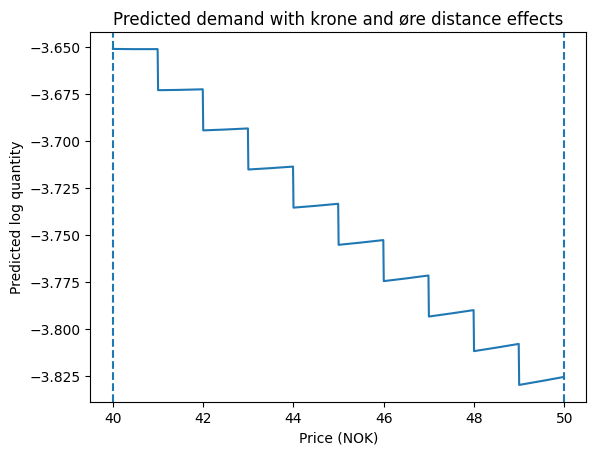

In [ ]:
plt.figure()
plt.plot(pred_df["price"], pred_df["log_q_hat"])
plt.axvline(40, linestyle="--")
plt.axvline(50, linestyle="--")
plt.xlabel("Price (NOK)")
plt.ylabel("Predicted log quantity")
plt.title("Predicted demand with krone and øre distance effects")
plt.show()

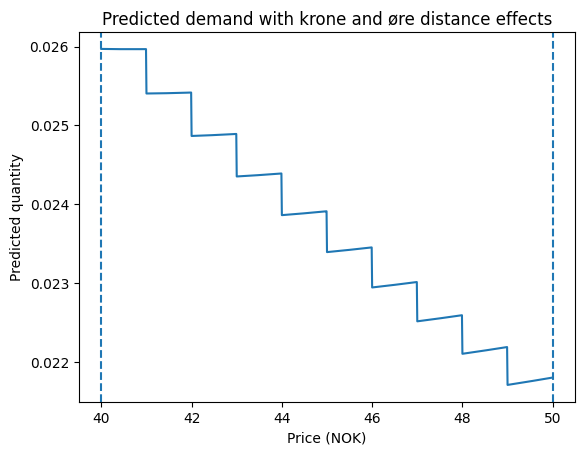

In [ ]:
plt.figure()
plt.plot(pred_df["price"], pred_df["q_hat"])
plt.axvline(40, linestyle="--")
plt.axvline(50, linestyle="--")
plt.xlabel("Price (NOK)")
plt.ylabel("Predicted quantity")
plt.title("Predicted demand with krone and øre distance effects")
plt.show()

In [ ]:
def krone_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dK: distance to lower decade in kroner (49.90 -> 9)
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to lower 10-krone threshold
    dK = 1 - (krone_part/10 - np.floor(krone_part / 10))
    # Distance to 0 ore
    dO = ore_part

    return dK

def ore_distance(price):
    """
    price: float or pd.Series (e.g. 49.90)

    returns:
    - dO: distance to 0 ore (49.90 -> 0.90)
    """

    price = np.asarray(price)

    # Krone and ore decomposition
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part

    # Distance to 0 ore
    dO = 1 - ore_part

    return dO

def take_krone_part(price):
    price = np.asarray(price)
    krone_part = np.floor(price).astype(int)
    return krone_part

def take_ore_part(price):
    price = np.asarray(price)
    krone_part = np.floor(price).astype(int)
    ore_part = price - krone_part
    return ore_part

In [ ]:
take_krone_part(29.8)

np.int64(29)

In [ ]:
take_krone_part(2.2)

np.int64(2)

In [ ]:
df_cat["krone_part"] = take_krone_part(df_cat["ppu"])
df_cat["ore_part"] = take_ore_part(df_cat["ppu"])

In [ ]:
df_cat['log_krone_part'] = np.log(df_cat["krone_part"] + 1)  # add 1 to avoid log(0)

In [ ]:
df_cat['log_ore_part'] = np.log(df_cat["ore_part"] + 1) # add 1 to avoid log(0)

In [ ]:
take_ore_part(2.2)

np.float64(0.20000000000000018)